<a href="https://colab.research.google.com/github/spbromberg/Project-3-DS-4002/blob/main/Scripts/03_Analysis_Paintings_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Paintings Project - Analysis
## Group 5 - DS 4002


**Notebook Overview:**

This notebook cleans 550 WikiArt paintings, resizes them to 224 x 224 pixels, and splits them by artist. It trains a ResNet-18 model to classify six artistic movements and evaluates its performance against a majority-class baseline using accuracy, macro-F1, per-class results, a confusion matrix, and a Grad-CAM example.

Imports

In [1]:
# General tools
import os
import zipfile
import copy

# Data handling
import numpy as np
import pandas as pd
from PIL import Image, ImageOps

# PyTorch and image transforms
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights

# Evaluation and plots
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

Image & Data Cleaning

In [3]:
CSV_PATH = "/content/wikiart_paintings.csv"
ZIP_PATH = "/content/wikiart_images_complete.zip"
DATA_DIR = "/content/wikiart_data"
CLEAN_DIR = "/content/wikiart_cleaned"

# Extract the image ZIP file.
os.makedirs(DATA_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(DATA_DIR)

# Load the painting information.
df = pd.read_csv(CSV_PATH)

clean_paths = []
readable_rows = []
bad_images = []

for index, row in df.iterrows():
    original_path = os.path.join(DATA_DIR, row["image_path"])

    try:
        with Image.open(original_path) as image:
            image = image.convert("RGB")
            image = ImageOps.pad(
                image,
                (224, 224),
                method=Image.Resampling.LANCZOS,
                color=(255, 255, 255)
            )

        # Save each cleaned image using its original relative folder path.
        relative_path = os.path.splitext(row["image_path"])[0] + ".jpg"
        cleaned_path = os.path.join(CLEAN_DIR, relative_path)
        os.makedirs(os.path.dirname(cleaned_path), exist_ok=True)
        image.save(cleaned_path, format="JPEG", quality=95)

        readable_rows.append(index)
        clean_paths.append(cleaned_path)

    except Exception as error:
        bad_images.append((row["image_path"], str(error)))

# Exclude rows whose images could not be opened and cleaned.
df = df.loc[readable_rows].copy().reset_index(drop=True)
df["full_image_path"] = clean_paths

print("Usable paintings:", len(df))
print("Unreadable images excluded:", len(bad_images))
print("\nPaintings per movement:")
print(df["movement"].value_counts())

if bad_images:
    print("\nImages that could not be cleaned:")
    for path, error in bad_images:
        print(path, "—", error)

print("\nCleaned data preview:")
display(df.head())

Usable paintings: 550
Unreadable images excluded: 0

Paintings per movement:
movement
Renaissance      100
Baroque          100
Impressionism    100
Romanticism       92
Other             88
Cubism            70
Name: count, dtype: int64

Cleaned data preview:


,title,artist_name,artist_slug,movement,artwork_styles,medium,artwork_url,image_url,image_path,full_image_path
0,Butcher's Stall with the Flight into Egypt,Pieter Aertsen,pieter-aertsen,Renaissance,Northern Renaissance,oil,https://www.wikiart.org/en/pieter-aertsen/butc...,https://uploads6.wikiart.org/images/pieter-aer...,images/pieter-aertsen--butcher-s-stall-with-th...,/content/wikiart_cleaned/images/pieter-aertsen...
1,The Egg Dance,Pieter Aertsen,pieter-aertsen,Renaissance,Northern Renaissance,oil; wood,https://www.wikiart.org/en/pieter-aertsen/the-...,https://uploads4.wikiart.org/images/pieter-aer...,images/pieter-aertsen--the-egg-dance-1552.jpg,/content/wikiart_cleaned/images/pieter-aertsen...
2,Cook in front of the Stove,Pieter Aertsen,pieter-aertsen,Renaissance,Northern Renaissance,oil; panel,https://www.wikiart.org/en/pieter-aertsen/cook...,https://uploads8.wikiart.org/images/pieter-aer...,images/pieter-aertsen--cook-in-front-of-the-st...,/content/wikiart_cleaned/images/pieter-aertsen...
3,The Cook,Pieter Aertsen,pieter-aertsen,Renaissance,Northern Renaissance,oil; panel,https://www.wikiart.org/en/pieter-aertsen/the-...,https://uploads8.wikiart.org/images/pieter-aer...,images/pieter-aertsen--the-cook-1559.jpg,/content/wikiart_cleaned/images/pieter-aertsen...
4,Peasants by the Hearth,Pieter Aertsen,pieter-aertsen,Renaissance,Northern Renaissance,oil; wood,https://www.wikiart.org/en/pieter-aertsen/peas...,https://uploads4.wikiart.org/images/pieter-aer...,images/pieter-aertsen--peasants-by-the-hearth-...,/content/wikiart_cleaned/images/pieter-aertsen...


Apply Training, Test, & Validation Splits to Data

In [5]:
# Assign each artist's paintings to only one split.
rng = np.random.default_rng(42)
artist_to_split = {}

for movement, movement_df in df.groupby("movement"):
    artists = movement_df["artist_slug"].dropna().unique().copy()
    rng.shuffle(artists)

    # Divide artists approximately 70% / 15% / 15%.
    n_artists = len(artists)
    n_train = max(1, min(n_artists - 2, round(0.70 * n_artists)))
    n_val = max(1, min(n_artists - n_train - 1, round(0.15 * n_artists)))

    for artist in artists[:n_train]:
        artist_to_split[artist] = "train"

    for artist in artists[n_train:n_train + n_val]:
        artist_to_split[artist] = "validation"

    for artist in artists[n_train + n_val:]:
        artist_to_split[artist] = "test"

# Add the split name and numeric model label to each painting.
df["split"] = df["artist_slug"].map(artist_to_split)

class_names = sorted(df["movement"].unique())
class_to_number = {name: number for number, name in enumerate(class_names)}
df["label"] = df["movement"].map(class_to_number)

train_df = df[df["split"] == "train"].copy().reset_index(drop=True)
val_df = df[df["split"] == "validation"].copy().reset_index(drop=True)
test_df = df[df["split"] == "test"].copy().reset_index(drop=True)

# Confirm that no artist appears in multiple splits.
train_artists = set(train_df["artist_slug"])
val_artists = set(val_df["artist_slug"])
test_artists = set(test_df["artist_slug"])

assert train_artists.isdisjoint(val_artists)
assert train_artists.isdisjoint(test_artists)
assert val_artists.isdisjoint(test_artists)

print("Rows per split:")
print(f"Training:   {len(train_df)} ({len(train_df) / len(df):.1%})")
print(f"Validation: {len(val_df)} ({len(val_df) / len(df):.1%})")
print(f"Test:       {len(test_df)} ({len(test_df) / len(df):.1%})")

print("\nPainting counts by movement and split:")
display(pd.crosstab(df["movement"], df["split"]))

Rows per split:
Training:   369 (67.1%)
Validation: 75 (13.6%)
Test:       106 (19.3%)

Painting counts by movement and split:


split,test,train,validation
movement,,,
Baroque,1,86,13
Cubism,13,45,12
Impressionism,15,69,16
Other,17,54,17
Renaissance,30,55,15
Romanticism,30,60,2


Create PyTorch Dataset & DataLoader

In [6]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Normalize images for the pretrained ResNet-18 model.
image_mean = [0.485, 0.456, 0.406]
image_std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomRotation(5, fill=255),
    transforms.ToTensor(),
    transforms.Normalize(image_mean, image_std)
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(image_mean, image_std)
])

class PaintingDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        image = Image.open(row["full_image_path"]).convert("RGB")
        image = self.transform(image)
        label = int(row["label"])
        return image, label

train_dataset = PaintingDataset(train_df, train_transform)
val_dataset = PaintingDataset(val_df, eval_transform)
test_dataset = PaintingDataset(test_df, eval_transform)

train_loader = DataLoader(
    train_dataset, batch_size=16, shuffle=True, num_workers=2,
    pin_memory=(device.type == "cuda")
)
val_loader = DataLoader(
    val_dataset, batch_size=16, shuffle=False, num_workers=2,
    pin_memory=(device.type == "cuda")
)
test_loader = DataLoader(
    test_dataset, batch_size=16, shuffle=False, num_workers=2,
    pin_memory=(device.type == "cuda")
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Using device: cpu
Training batches: 24
Validation batches: 5
Test batches: 7


Establish Majority Class Baseline

In [7]:
from sklearn.metrics import accuracy_score, f1_score

# Find the most common movement in the training data.
majority_class = train_df["movement"].mode()[0]

# Predict that movement for every painting in the test set.
baseline_predictions = [majority_class] * len(test_df)

# Compare the baseline predictions with the actual test labels.
baseline_accuracy = accuracy_score(
    test_df["movement"],
    baseline_predictions
)
baseline_macro_f1 = f1_score(
    test_df["movement"],
    baseline_predictions,
    average="macro",
    zero_division=0
)

print("Majority class:", majority_class)
print(f"Baseline test accuracy: {baseline_accuracy:.3f}")
print(f"Baseline test macro-F1: {baseline_macro_f1:.3f}")

Majority class: Baroque
Baseline test accuracy: 0.009
Baseline test macro-F1: 0.003


Create Majority-Class Baseline (For Comparison with ResNet-18 Later)

In [9]:
from sklearn.metrics import accuracy_score, f1_score

# Find the most common movement in the training data.
majority_class = train_df["movement"].mode()[0]

# Predict that movement for every painting in the test set.
baseline_predictions = [majority_class] * len(test_df)

# Compare the baseline predictions with the actual test labels.
baseline_accuracy = accuracy_score(
    test_df["movement"],
    baseline_predictions
)
baseline_macro_f1 = f1_score(
    test_df["movement"],
    baseline_predictions,
    average="macro",
    zero_division=0
)

print("Majority class:", majority_class)
print(f"Baseline test accuracy: {baseline_accuracy:.3f}")
print(f"Baseline test macro-F1: {baseline_macro_f1:.3f}")

Majority class: Baroque
Baseline test accuracy: 0.009
Baseline test macro-F1: 0.003


In [10]:
majority_class = train_df["movement"].mode()[0]
print("Majority class:", majority_class)

Majority class: Baroque


Setup ResNet-18 Model for Analysis

In [11]:
# Load ResNet-18 with pretrained ImageNet weights.
model = resnet18(weights=ResNet18_Weights.DEFAULT)

# Freeze the pretrained layers so only the new classifier is trained.
for parameter in model.parameters():
    parameter.requires_grad = False

# Replace the final layer with one output for each art movement.
model.fc = nn.Linear(model.fc.in_features, len(class_names))
model = model.to(device)

# Give less common training classes more weight in the loss calculation.
class_counts = (
    train_df["label"]
    .value_counts()
    .sort_index()
    .to_numpy()
)

class_weights = len(train_df) / (len(class_names) * class_counts)
class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)

loss_function = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.fc.parameters(), lr=0.001)

print("Model ready.")
print("Classes:", class_names)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 140MB/s]


Model ready.
Classes: ['Baroque', 'Cubism', 'Impressionism', 'Other', 'Renaissance', 'Romanticism']


Train ResNet-18 Model & Use Validation Set to Preserve the Best Version

(Test Set Reamins Untouched Until Final Evaluation)

In [12]:
EPOCHS = 8
best_val_f1 = -1
best_model_state = copy.deepcopy(model.state_dict())

for epoch in range(EPOCHS):
    # Train the classifier while keeping the pretrained layers fixed.
    model.eval()       # Keeps frozen ResNet batch-normalization layers fixed.
    model.fc.train()
    total_train_loss = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = loss_function(outputs, labels)
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()

    # Measure performance on the validation set.
    model.eval()
    val_predictions = []
    val_actual = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            outputs = model(images)
            predictions = outputs.argmax(dim=1).cpu().tolist()

            val_predictions.extend(predictions)
            val_actual.extend(labels.tolist())

    val_macro_f1 = f1_score(
        val_actual,
        val_predictions,
        average="macro",
        zero_division=0
    )

    average_loss = total_train_loss / len(train_loader)
    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Training loss: {average_loss:.3f} | "
        f"Validation macro-F1: {val_macro_f1:.3f}"
    )

    # Save the model whenever validation macro-F1 improves.
    if val_macro_f1 > best_val_f1:
        best_val_f1 = val_macro_f1
        best_model_state = copy.deepcopy(model.state_dict())

# Restore the best-performing version from training.
model.load_state_dict(best_model_state)
print(f"\nBest validation macro-F1: {best_val_f1:.3f}")

Epoch 1/8 | Training loss: 1.758 | Validation macro-F1: 0.252
Epoch 2/8 | Training loss: 1.303 | Validation macro-F1: 0.237
Epoch 3/8 | Training loss: 1.132 | Validation macro-F1: 0.320
Epoch 4/8 | Training loss: 1.018 | Validation macro-F1: 0.342
Epoch 5/8 | Training loss: 0.959 | Validation macro-F1: 0.332
Epoch 6/8 | Training loss: 0.839 | Validation macro-F1: 0.233
Epoch 7/8 | Training loss: 0.897 | Validation macro-F1: 0.373
Epoch 8/8 | Training loss: 0.784 | Validation macro-F1: 0.320

Best validation macro-F1: 0.373


Evaluate Best Version of the Model on the Untouchued Test Set

(Reports Final Accuracy, Macro-F1, Per-Class Precision, & Confusion Matrix)

Test accuracy: 0.358
Test macro-F1: 0.337

Per-class results:
               precision    recall  f1-score   support

      Baroque       0.08      1.00      0.14         1
       Cubism       0.54      0.54      0.54        13
Impressionism       0.78      0.47      0.58        15
        Other       0.14      0.18      0.16        17
  Renaissance       0.42      0.60      0.49        30
  Romanticism       0.29      0.07      0.11        30

     accuracy                           0.36       106
    macro avg       0.37      0.47      0.34       106
 weighted avg       0.40      0.36      0.35       106



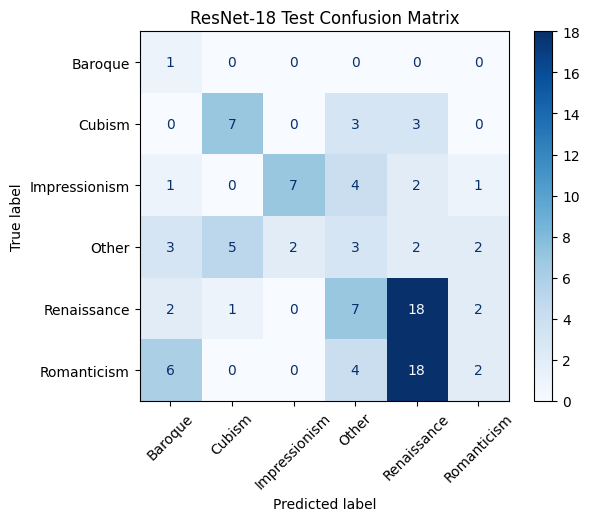

In [13]:
model.eval()
test_predictions = []
test_actual = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        predictions = outputs.argmax(dim=1).cpu().tolist()

        test_predictions.extend(predictions)
        test_actual.extend(labels.tolist())

test_accuracy = accuracy_score(test_actual, test_predictions)
test_macro_f1 = f1_score(
    test_actual,
    test_predictions,
    average="macro",
    zero_division=0
)

print(f"Test accuracy: {test_accuracy:.3f}")
print(f"Test macro-F1: {test_macro_f1:.3f}")
print("\nPer-class results:")
print(classification_report(
    test_actual,
    test_predictions,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

# Show which movements the model confused with one another.
matrix = confusion_matrix(
    test_actual,
    test_predictions,
    labels=range(len(class_names))
)

display = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=class_names
)
display.plot(cmap="Blues", xticks_rotation=45)
plt.title("ResNet-18 Test Confusion Matrix")
plt.show()

Grad-CAM Visualization

(Inspects Which Aspects of the Test Paintings Influence the Model's Prediction)

Actual movement: Renaissance
Predicted movement: Cubism


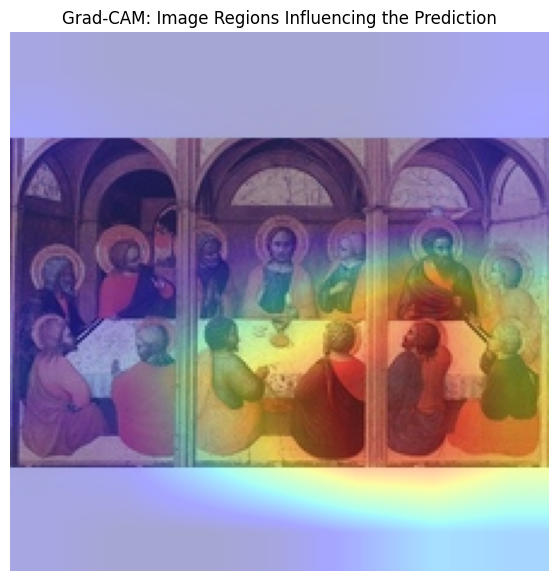

In [15]:
# Select a painting from the test set.
example = test_df.iloc[0]
original_image = Image.open(example["full_image_path"]).convert("RGB")
input_tensor = eval_transform(original_image).unsqueeze(0).to(device)

# Enable gradient tracking on the input tensor for Grad-CAM
input_tensor.requires_grad_(True)

# Store the layer's activations and their gradients.
activations = []
gradients = []

def save_activation(module, inputs, output):
    activations.append(output)
    output.register_hook(lambda gradient: gradients.append(gradient))

# Use the final ResNet block for Grad-CAM.
hook = model.layer4[-1].register_forward_hook(save_activation)

model.eval()
model.zero_grad()

scores = model(input_tensor)
predicted_label = scores.argmax(dim=1).item()

# Calculate gradients for the predicted class.
scores[0, predicted_label].backward()

activation = activations[0]
gradient = gradients[0]

# Weight feature maps by their average gradients.
weights = gradient.mean(dim=(2, 3), keepdim=True)
heatmap = F.relu((weights * activation).sum(dim=1, keepdim=True))

# Resize the heatmap to match the painting.
heatmap = F.interpolate(
    heatmap,
    size=(224, 224),
    mode="bilinear",
    align_corners=False
)
heatmap = heatmap.squeeze().detach().cpu().numpy()
heatmap = heatmap / (heatmap.max() + 1e-8)

hook.remove()

print("Actual movement:", example["movement"])
print("Predicted movement:", class_names[predicted_label])

plt.figure(figsize=(7, 7))
plt.imshow(original_image.resize((224, 224)))
plt.imshow(heatmap, cmap="jet", alpha=0.35)
plt.axis("off")
plt.title("Grad-CAM: Image Regions Influencing the Prediction")
plt.show()

Final Model Comparison with Baseline

In [17]:
# Score the baseline on the test set after model selection is complete.
baseline_label = class_to_number[majority_class]
baseline_predictions = [baseline_label] * len(test_actual)

baseline_accuracy = accuracy_score(test_actual, baseline_predictions)
baseline_macro_f1 = f1_score(
    test_actual,
    baseline_predictions,
    labels=range(len(class_names)),
    average="macro",
    zero_division=0
)

results = pd.DataFrame({
    "Model": ["Majority-class baseline", "ResNet-18"],
    "Test accuracy": [baseline_accuracy, test_accuracy],
    "Test macro-F1": [baseline_macro_f1, test_macro_f1]
})

# Explicitly use IPython's display to avoid the overwritten variable name conflict
import IPython
IPython.display.display(results)

,Model,Test accuracy,Test macro-F1
0,Majority-class baseline,0.009434,0.003115
1,ResNet-18,0.358491,0.337301
